# 🚦 FedMARL-ATSC · Phase 1 Demo
## Federated Learning with Decoupled Architecture (No Real Simulator Required)

---

### Purpose

This notebook **proves the federated coordination architecture works end-to-end** before any real CityFlow/SUMO data arrives. The RL training loop is intentionally mocked — we focus entirely on:

1. The **decoupled neural network** (`shared backbone` ↔ `local policy head`).
2. The **FedAvg aggregation algorithm** on the server.
3. The **personalisation property**: only backbone weights travel over the network; policy heads stay private.

### Why Decoupled Architecture Prevents Negative Transfer

> **Negative Transfer** occurs when knowledge from one intersection *hurts* the performance of another because their traffic dynamics are structurally incompatible (e.g., a 3-way T-junction agent updating a 4-way arterial agent's weights).

By splitting the network into two parts:

| Part | Federated? | Learns |
|---|---|---|
| `shared_feature_extractor` | ✅ Yes — averaged globally | Universal traffic representations (queue length patterns, phase timing) |
| `local_policy_head` | ❌ No — stays on device | Intersection-specific decision logic (phase space, topology quirks) |

The server **never sees** the policy head. Each intersection agent retains its own local head, allowing personalisation while still benefiting from the globally shared backbone.

```
  Agent A (T-junction)        Agent B (4-way)         Agent C (arterial)
  ┌─────────────────┐         ┌─────────────────┐      ┌─────────────────┐
  │ shared backbone │──┐   ┌──│ shared backbone │──┐ ┌─│ shared backbone │
  │   (federated)   │  │   │  │   (federated)   │  │ │ │   (federated)   │
  ├─────────────────┤  │   │  ├─────────────────┤  │ │ ├─────────────────┤
  │  local head A   │  │   │  │  local head B   │  │ │ │  local head C   │
  │     (private)   │  │   │  │     (private)   │  │ │ │     (private)   │
  └─────────────────┘  │   │  └─────────────────┘  │ │ └─────────────────┘
                       ▼   ▼                       ▼ ▼
                   ┌───────────────────────────────────┐
                   │        Federated Server           │
                   │   FedAvg( w_A, w_B, w_C ) → w*    │
                   └───────────────────────────────────┘
```


---
## Cell 1 · Imports & Reproducibility

In [1]:
import copy
import random
from typing import Dict, List, OrderedDict

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# ── Reproducibility ──────────────────────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device : {DEVICE}")
print(f"PyTorch      : {torch.__version__}")


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/traitlets/config/application.py", line 1075, in launch_instance
    app.start()
  File "/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/ipyk

Using device : cpu
PyTorch      : 2.1.1


---
## Cell 2 · Hyperparameters

All tuneable constants live here so experiments are reproducible and easy to sweep.

In [2]:
# ── Environment dimensions ────────────────────────────────────────────────────
# obs_dim  : feature vector size fed into the network
#             = num_incoming_lanes × features_per_lane (queue, speed, density)
# num_phases: action space size (number of controllable signal phases)
OBS_DIM   = 12   # e.g. 4 lanes × 3 features
NUM_PHASES = 4   # 4-phase signal (N/S green, E/W green, left-turn phases …)

# ── Network architecture ──────────────────────────────────────────────────────
HIDDEN_DIM    = 64   # neurons in each hidden layer of the shared backbone
BACKBONE_OUT  = 32   # output dimensionality of the shared feature extractor

# ── Federated Learning ───────────────────────────────────────────────────────
NUM_AGENTS        = 3    # number of edge-node agents (intersections)
NUM_FL_ROUNDS     = 5    # total federated communication rounds
LOCAL_TRAIN_STEPS = 10   # local SGD steps per agent per round
LOCAL_BATCH_SIZE  = 16   # mock batch size for the dummy forward pass
LEARNING_RATE     = 1e-3

print("Hyperparameters loaded ✓")

Hyperparameters loaded ✓


---
## Cell 3 · `TrafficAgentNet` — Decoupled Neural Network

The key architectural decision: **two clearly named sub-modules**.

* `shared_feature_extractor` — the *backbone*. Federated and updated globally.
* `local_policy_head`        — the *head*.    Private to each intersection node.

Using `nn.Sequential` with named modules (not a flat list) makes it trivial to
extract only the backbone `state_dict` without touching the head.

In [3]:
class TrafficAgentNet(nn.Module):
    """
    Decoupled neural network for a single traffic-signal agent.

    Architecture
    ------------
    Input  (obs_dim,)
      │
      ▼
    shared_feature_extractor
      Linear(obs_dim → hidden_dim) → ReLU
      Linear(hidden_dim → backbone_out) → ReLU
      │
      ▼  ← only these weights travel to the FL server
    local_policy_head
      Linear(backbone_out → num_phases)
      │
      ▼
    Output (num_phases,)  — raw Q-values / logits

    Parameters
    ----------
    obs_dim      : int  Observation vector size.
    hidden_dim   : int  Hidden layer width in the backbone.
    backbone_out : int  Output dimensionality of the backbone.
    num_phases   : int  Number of controllable signal phases (action space).
    """

    def __init__(
        self,
        obs_dim:      int = OBS_DIM,
        hidden_dim:   int = HIDDEN_DIM,
        backbone_out: int = BACKBONE_OUT,
        num_phases:   int = NUM_PHASES,
    ) -> None:
        super().__init__()

        # ── Shared backbone (federated) ───────────────────────────────────────
        self.shared_feature_extractor = nn.Sequential(
            nn.Linear(obs_dim,     hidden_dim),  nn.ReLU(),
            nn.Linear(hidden_dim,  backbone_out), nn.ReLU(),
        )

        # ── Local policy head (private, stays on device) ──────────────────────
        self.local_policy_head = nn.Sequential(
            nn.Linear(backbone_out, num_phases),
        )

    def forward(self, obs: torch.Tensor) -> torch.Tensor:
        """
        Forward pass through both sub-modules.

        Args:
            obs: Observation tensor of shape (batch, obs_dim).

        Returns:
            logits: Shape (batch, num_phases). Interpreted as Q-values or
                    action logits depending on the RL algorithm.
        """
        features = self.shared_feature_extractor(obs)
        logits   = self.local_policy_head(features)
        return logits


# ── Quick sanity check ────────────────────────────────────────────────────────
demo_net = TrafficAgentNet().to(DEVICE)
demo_obs = torch.randn(LOCAL_BATCH_SIZE, OBS_DIM, device=DEVICE)
demo_out = demo_net(demo_obs)

print(demo_net)
print(f"\nInput  shape : {demo_obs.shape}")
print(f"Output shape : {demo_out.shape}")
print("\nTrafficAgentNet instantiated ✓")

TrafficAgentNet(
  (shared_feature_extractor): Sequential(
    (0): Linear(in_features=12, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
  )
  (local_policy_head): Sequential(
    (0): Linear(in_features=32, out_features=4, bias=True)
  )
)

Input  shape : torch.Size([16, 12])
Output shape : torch.Size([16, 4])

TrafficAgentNet instantiated ✓


---
## Cell 4 · `MockNodeAgent` — Edge-Node Client

In the real system an agent wraps a CityFlow env + a PPO/DQN trainer.
Here we mock those with random tensors and dummy MSE loss so we can
validate the entire FL pipeline independently of the simulator.

### Key method contract

| Method | Description |
|---|---|
| `train_local_step()` | One SGD update on mock data; returns scalar loss |
| `get_shared_weights()` | Returns `state_dict` of **backbone only** |
| `set_shared_weights(w)` | Loads backbone weights received from server |


In [4]:
class MockNodeAgent:
    """
    Simulates an edge-node RL agent at a single traffic intersection.

    The RL environment interaction is replaced by random tensors so the
    federated coordination logic can be validated in isolation.

    Parameters
    ----------
    agent_id      : str   Human-readable label (e.g. 'intersection_A').
    obs_dim       : int   Observation vector dimension.
    num_phases    : int   Number of signal phases (action space size).
    learning_rate : float Adam learning rate for local optimiser.
    noise_scale   : float Std-dev of Gaussian noise added to mock targets,
                          simulating distinct per-intersection traffic dynamics.
    """

    def __init__(
        self,
        agent_id:      str,
        obs_dim:       int   = OBS_DIM,
        num_phases:    int   = NUM_PHASES,
        learning_rate: float = LEARNING_RATE,
        noise_scale:   float = 0.1,
    ) -> None:
        self.agent_id    = agent_id
        self.noise_scale = noise_scale

        # Each agent maintains its OWN network — backbone + private head
        self.net       = TrafficAgentNet(obs_dim=obs_dim, num_phases=num_phases).to(DEVICE)
        self.optimizer = optim.Adam(self.net.parameters(), lr=learning_rate)
        self.criterion = nn.MSELoss()

        self._loss_history: List[float] = []

    # ── Local training ────────────────────────────────────────────────────────

    def train_local_step(self) -> float:
        """
        Perform one local SGD update on mock traffic data.

        In the real system this call would:
          1. Sample a mini-batch from a replay buffer populated by CityFlow.
          2. Compute TD-error (DQN) or policy gradient (PPO).
          3. Back-propagate through both backbone and policy head.

        Here we:
          1. Sample random 'observations' as mock traffic states.
          2. Compute network output (forward pass through full network).
          3. Create a mock 'target' with agent-specific noise to simulate
             heterogeneous traffic distributions across intersections.
          4. Minimise MSE loss and back-propagate.

        Returns
        -------
        float : Scalar loss value for this update step.
        """
        self.net.train()
        self.optimizer.zero_grad()

        # Mock traffic state: (batch, obs_dim) — in reality from env.step()
        mock_obs = torch.randn(LOCAL_BATCH_SIZE, OBS_DIM, device=DEVICE)

        # Forward pass through the full network
        logits = self.net(mock_obs)   # shape: (batch, num_phases)

        # Mock target: intersection-specific distribution (heterogeneity proxy)
        # Each agent has a unique noise_scale so their local data distributions
        # differ, mimicking real-world intersection heterogeneity.
        mock_target = torch.randn_like(logits) * self.noise_scale

        loss = self.criterion(logits, mock_target)
        loss.backward()
        self.optimizer.step()

        loss_val = loss.item()
        self._loss_history.append(loss_val)
        return loss_val

    # ── Federated weight exchange ─────────────────────────────────────────────

    def get_shared_weights(self) -> Dict[str, torch.Tensor]:
        """
        Extract ONLY the shared backbone weights for federation.

        The local_policy_head weights are intentionally excluded — they
        encode intersection-specific decision logic and must NOT be averaged
        with other intersections (doing so would cause Negative Transfer).

        Returns
        -------
        dict : state_dict of `shared_feature_extractor` with tensors moved to CPU
               (network communication is CPU-side in Flower / gRPC).
        """
        # deep-copy to avoid mutating the live model when the server modifies it
        return copy.deepcopy(
            self.net.shared_feature_extractor.state_dict()
        )

    def set_shared_weights(self, global_weights: Dict[str, torch.Tensor]) -> None:
        """
        Load the globally aggregated backbone weights broadcast by the server.

        Only the backbone is updated; local_policy_head remains unchanged.
        This is the key personalisation step: each agent keeps its own
        fine-tuned head while benefiting from the globally improved backbone.

        Parameters
        ----------
        global_weights : dict  state_dict from FederatedServer.aggregate().
        """
        self.net.shared_feature_extractor.load_state_dict(global_weights)

    # ── Utilities ─────────────────────────────────────────────────────────────

    @property
    def loss_history(self) -> List[float]:
        """All recorded loss values across training steps."""
        return self._loss_history

    def __repr__(self) -> str:
        return f"MockNodeAgent(id={self.agent_id!r}, noise_scale={self.noise_scale})"


print("MockNodeAgent class defined ✓")

MockNodeAgent class defined ✓


---
## Cell 5 · `FederatedServer` — Global Coordinator

The server never touches raw traffic data — it only ever sees **model weights**.

### FedAvg Algorithm (McMahan et al., 2017)

Given $K$ clients each contributing weights $w_k$, the global update is:

$$w^* = \frac{1}{K} \sum_{k=1}^{K} w_k$$

In a production system we would weight by local dataset size $n_k$:

$$w^* = \sum_{k=1}^{K} \frac{n_k}{\sum_j n_j} \cdot w_k$$

Since we use mock data with identical batch sizes, the uniform average is equivalent.

In [5]:
class FederatedServer:
    """
    Central coordinator for the Federated Learning loop.

    Responsibilities
    ----------------
    * Receive backbone weights from all participating agents.
    * Aggregate them via FedAvg (or pluggable strategies).
    * Broadcast the resulting global weights back to agents.

    The server holds NO traffic data, NO environment, and NO policy head.
    It is a pure parameter coordinator — privacy-preserving by design.

    Parameters
    ----------
    clients : list[MockNodeAgent]  Registered edge-node agents.
    """

    def __init__(self, clients: List[MockNodeAgent]) -> None:
        self.clients        = clients
        self.global_weights: Dict[str, torch.Tensor] | None = None
        self._round_history: List[Dict] = []

    # ── Aggregation ───────────────────────────────────────────────────────────

    def aggregate(self, list_of_weights: List[Dict[str, torch.Tensor]]) -> Dict[str, torch.Tensor]:
        """
        FedAvg: compute the element-wise mean of all client backbone weights.

        Parameters
        ----------
        list_of_weights : list of state_dicts, one per participating client.

        Returns
        -------
        dict : Averaged state_dict to be broadcast to all clients.

        Notes
        -----
        torch.stack + torch.mean is used instead of an explicit loop for
        clarity and to keep the averaging on the same dtype as the model.
        """
        if not list_of_weights:
            raise ValueError("aggregate() received an empty list of weights.")

        # Collect all parameter tensors by layer name
        # Every client uses an identical backbone architecture, so their
        # state_dict keys are always aligned.
        avg_weights: Dict[str, torch.Tensor] = {}

        for key in list_of_weights[0].keys():
            # Stack all clients' tensors for this key: shape (num_clients, *param_shape)
            stacked = torch.stack([w[key].float() for w in list_of_weights], dim=0)
            avg_weights[key] = stacked.mean(dim=0)   # element-wise FedAvg

        self.global_weights = avg_weights
        return avg_weights

    # ── Broadcast ─────────────────────────────────────────────────────────────

    def broadcast(self) -> None:
        """
        Push the aggregated global backbone weights to every registered client.

        In production (Flower / gRPC) this would serialise the weights,
        transmit them over the network, and deserialise on the client side.
        Here we directly call set_shared_weights() to simulate the process.

        Raises
        ------
        RuntimeError : If called before the first aggregate().
        """
        if self.global_weights is None:
            raise RuntimeError("No global weights to broadcast. Call aggregate() first.")

        for client in self.clients:
            # deep-copy so each client gets an independent tensor (no aliasing)
            client.set_shared_weights(copy.deepcopy(self.global_weights))

    # ── Round bookkeeping ─────────────────────────────────────────────────────

    def log_round(self, round_idx: int, losses: Dict[str, List[float]]) -> None:
        """Record per-round metrics for later plotting."""
        self._round_history.append({
            "round":  round_idx,
            "losses": {k: float(np.mean(v)) for k, v in losses.items()},
        })

    @property
    def round_history(self) -> List[Dict]:
        """Recorded round-level metrics."""
        return self._round_history

    def __repr__(self) -> str:
        return f"FederatedServer(num_clients={len(self.clients)})"


print("FederatedServer class defined ✓")

FederatedServer class defined ✓


---
## Cell 6 · Initialisation

Spin up 3 agents representing heterogeneous intersections:

| Agent | Intersection type | Noise scale (heterogeneity proxy) |
|---|---|---|
| `intersection_A` | 4-way arterial (high throughput) | 0.05 |
| `intersection_B` | T-junction (medium) | 0.15 |
| `intersection_C` | Multi-lane complex | 0.30 |

In [6]:
# ── Agent initialisation ──────────────────────────────────────────────────────
# noise_scale differs per agent to simulate distinct traffic distributions
# (heterogeneous intersections) — higher noise = more non-IID local data.
agents = [
    MockNodeAgent(agent_id="intersection_A", noise_scale=0.05),   # arterial, stable
    MockNodeAgent(agent_id="intersection_B", noise_scale=0.15),   # T-junction, medium variance
    MockNodeAgent(agent_id="intersection_C", noise_scale=0.30),   # complex, high variance
]

# ── Server initialisation ─────────────────────────────────────────────────────
server = FederatedServer(clients=agents)

print(f"Server  : {server}")
for a in agents:
    print(f"  Agent : {a}")

# ── Confirm backbone is the ONLY part that will be shared ─────────────────────
sample_shared = agents[0].get_shared_weights()
print("\nKeys in the shared (federated) weight packet:")
for k, v in sample_shared.items():
    print(f"  {k:40s}  shape={tuple(v.shape)}")

print("\nKeys that remain LOCAL (never sent to server):")
all_keys    = set(agents[0].net.state_dict().keys())
shared_keys = set(sample_shared.keys())
# local_policy_head keys are prefixed differently so we map them back
local_keys  = [
    k for k in agents[0].net.state_dict()
    if not k.startswith("shared_feature_extractor")
]
for k in local_keys:
    v = agents[0].net.state_dict()[k]
    print(f"  {k:40s}  shape={tuple(v.shape)}  🔒 private")

Server  : FederatedServer(num_clients=3)
  Agent : MockNodeAgent(id='intersection_A', noise_scale=0.05)
  Agent : MockNodeAgent(id='intersection_B', noise_scale=0.15)
  Agent : MockNodeAgent(id='intersection_C', noise_scale=0.3)

Keys in the shared (federated) weight packet:
  0.weight                                  shape=(64, 12)
  0.bias                                    shape=(64,)
  2.weight                                  shape=(32, 64)
  2.bias                                    shape=(32,)

Keys that remain LOCAL (never sent to server):
  local_policy_head.0.weight                shape=(4, 32)  🔒 private
  local_policy_head.0.bias                  shape=(4,)  🔒 private


---
## Cell 7 · Federated Simulation Loop

5 communication rounds × 10 local SGD steps per agent = 50 total gradient updates per agent.

```
for round in 1..NUM_FL_ROUNDS:
    for each agent:
        agent.train_local_step() × LOCAL_TRAIN_STEPS
    server.aggregate([agent.get_shared_weights() for agent])
    server.broadcast()   ← pushes global backbone to all agents
```

In [7]:
SEPARATOR = "═" * 65

# Dict to record per-round average losses for plotting
round_avg_losses: Dict[str, List[float]] = {a.agent_id: [] for a in agents}

print(SEPARATOR)
print(f" FedMARL-ATSC · Federated Learning Simulation")
print(f" {NUM_AGENTS} agents · {NUM_FL_ROUNDS} rounds · {LOCAL_TRAIN_STEPS} local steps / round")
print(SEPARATOR)

for fl_round in range(1, NUM_FL_ROUNDS + 1):
    print(f"\n{'─'*65}")
    print(f" 🔄  Communication Round {fl_round} / {NUM_FL_ROUNDS}")
    print(f"{'─'*65}")

    # ── Step A: Local training ─────────────────────────────────────────────
    # Each agent trains independently on its own (mock) data.
    # In production: runs real RL updates against CityFlow transitions.
    round_losses: Dict[str, List[float]] = {a.agent_id: [] for a in agents}

    for agent in agents:
        step_losses = []
        for step in range(LOCAL_TRAIN_STEPS):
            loss = agent.train_local_step()
            step_losses.append(loss)

        avg_loss = float(np.mean(step_losses))
        round_losses[agent.agent_id] = step_losses
        round_avg_losses[agent.agent_id].append(avg_loss)

        print(
            f"  [{agent.agent_id}]  "
            f"local steps={LOCAL_TRAIN_STEPS}  "
            f"avg_loss={avg_loss:.4f}  "
            f"last_loss={step_losses[-1]:.4f}"
        )

    # ── Step B: Collect shared weights from all agents ─────────────────────
    # ONLY the backbone state_dict is transmitted — policy heads stay local.
    shared_weight_packets = [agent.get_shared_weights() for agent in agents]
    print(f"\n  📤 Collected shared backbone weights from {len(agents)} agents.")

    # ── Step C: Server aggregates via FedAvg ──────────────────────────────
    global_weights = server.aggregate(shared_weight_packets)
    print(f"  ⚙️  FedAvg aggregation complete — {len(global_weights)} parameter tensors averaged.")

    # ── Step D: Broadcast updated global backbone to all agents ───────────
    server.broadcast()
    print(f"  📥 Global backbone broadcast to all {len(agents)} agents.")

    # ── Step E: Log round metrics ─────────────────────────────────────────
    server.log_round(fl_round, round_losses)

print(f"\n{SEPARATOR}")
print(" ✅  Federated simulation completed without errors!")
print(SEPARATOR)

═════════════════════════════════════════════════════════════════
 FedMARL-ATSC · Federated Learning Simulation
 3 agents · 5 rounds · 10 local steps / round
═════════════════════════════════════════════════════════════════

─────────────────────────────────────────────────────────────────
 🔄  Communication Round 1 / 5
─────────────────────────────────────────────────────────────────
  [intersection_A]  local steps=10  avg_loss=0.0135  last_loss=0.0076
  [intersection_B]  local steps=10  avg_loss=0.0431  last_loss=0.0317
  [intersection_C]  local steps=10  avg_loss=0.1054  last_loss=0.0941

  📤 Collected shared backbone weights from 3 agents.
  ⚙️  FedAvg aggregation complete — 4 parameter tensors averaged.
  📥 Global backbone broadcast to all 3 agents.

─────────────────────────────────────────────────────────────────
 🔄  Communication Round 2 / 5
─────────────────────────────────────────────────────────────────
  [intersection_A]  local steps=10  avg_loss=0.0045  last_loss=0.0030
  [

---
## Cell 8 · Verification — Shared Backbone Synchronised, Private Heads Diverged

After broadcasting, all agents must share **identical backbone weights** but
retain **different policy head weights** (personalisation).

In [8]:
print("=" * 65)
print(" Post-Training Weight Verification")
print("=" * 65)

# ── 1. Backbone must be identical across all agents ───────────────────────────
print("\n[1] Backbone (shared_feature_extractor) — should be IDENTICAL:")
ref_backbone = agents[0].get_shared_weights()
all_match = True
for agent in agents[1:]:
    other_backbone = agent.get_shared_weights()
    for key in ref_backbone:
        if not torch.allclose(ref_backbone[key], other_backbone[key]):
            print(f"  ✗ MISMATCH in {key} between {agents[0].agent_id} and {agent.agent_id}")
            all_match = False

if all_match:
    print(f"  ✓ All {len(agents)} agents share identical backbone weights after FedAvg broadcast.")

# ── 2. Policy heads must DIFFER (personalisation) ─────────────────────────────
print("\n[2] Policy head (local_policy_head) — should be DIFFERENT:")
ref_head = agents[0].net.local_policy_head.state_dict()
all_differ = True
for agent in agents[1:]:
    other_head = agent.net.local_policy_head.state_dict()
    for key in ref_head:
        if torch.allclose(ref_head[key], other_head[key]):
            print(f"  ⚠ UNEXPECTED MATCH in {key} between {agents[0].agent_id} and {agent.agent_id}")
            all_differ = False

if all_differ:
    print(f"  ✓ Policy heads diverged as expected — personalisation is working.")

print("\nConclusion: Decoupled architecture successfully enforces the \n"
      "            shared-backbone / private-head separation. 🎉")

 Post-Training Weight Verification

[1] Backbone (shared_feature_extractor) — should be IDENTICAL:
  ✓ All 3 agents share identical backbone weights after FedAvg broadcast.

[2] Policy head (local_policy_head) — should be DIFFERENT:
  ✓ Policy heads diverged as expected — personalisation is working.

Conclusion: Decoupled architecture successfully enforces the 
            shared-backbone / private-head separation. 🎉


---
## Cell 9 · Visualisation — Loss Curves Across Rounds

FileNotFoundError: [Errno 2] No such file or directory: '../data/fl_demo_loss_curves.png'

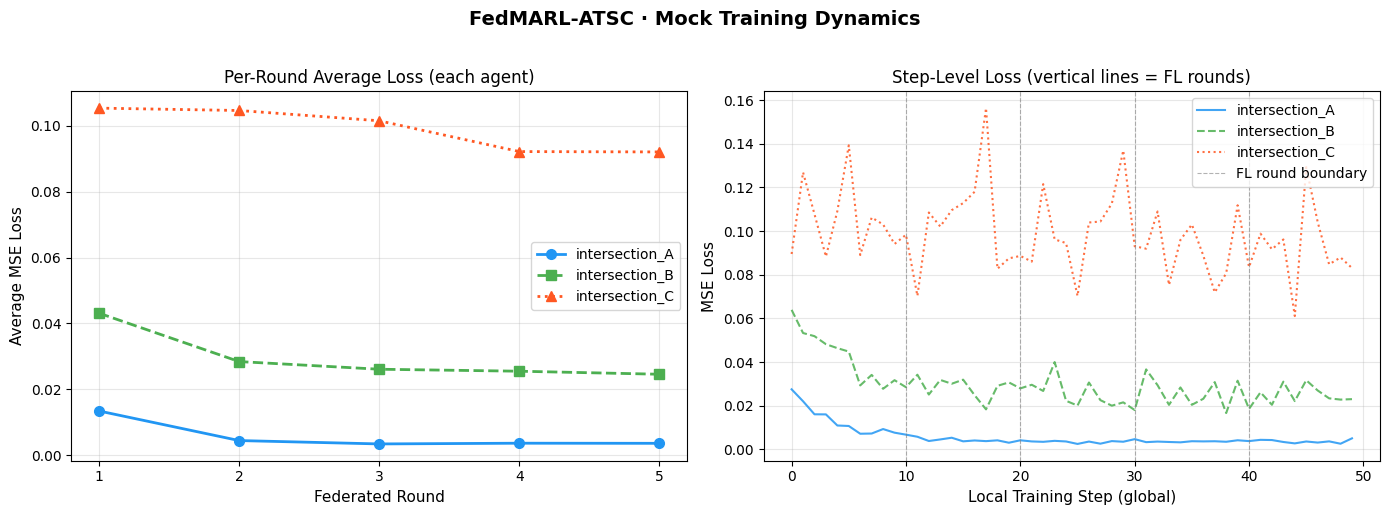

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(
    "FedMARL-ATSC · Mock Training Dynamics",
    fontsize=14, fontweight="bold", y=1.02
)

colors = ["#2196F3", "#4CAF50", "#FF5722"]  # blue, green, red-orange
linestyles = ["-", "--", ":"]
markers    = ["o",  "s",  "^"]

# ── Left: Per-round average loss ──────────────────────────────────────────────
ax = axes[0]
rounds = list(range(1, NUM_FL_ROUNDS + 1))
for i, agent in enumerate(agents):
    ax.plot(
        rounds,
        round_avg_losses[agent.agent_id],
        label=agent.agent_id,
        color=colors[i],
        linestyle=linestyles[i],
        marker=markers[i],
        linewidth=2,
        markersize=7,
    )
ax.set_xlabel("Federated Round", fontsize=11)
ax.set_ylabel("Average MSE Loss", fontsize=11)
ax.set_title("Per-Round Average Loss (each agent)", fontsize=12)
ax.set_xticks(rounds)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

# ── Right: Full step-level loss history (all rounds concatenated) ─────────────
ax2 = axes[1]
for i, agent in enumerate(agents):
    ax2.plot(
        agent.loss_history,
        label=agent.agent_id,
        color=colors[i],
        linestyle=linestyles[i],
        linewidth=1.5,
        alpha=0.85,
    )

# Draw vertical lines at round boundaries
total_steps = NUM_FL_ROUNDS * LOCAL_TRAIN_STEPS
for r in range(1, NUM_FL_ROUNDS):
    ax2.axvline(
        x=r * LOCAL_TRAIN_STEPS,
        color="grey", linestyle="--", linewidth=0.8, alpha=0.6,
        label="FL round boundary" if r == 1 else None
    )

ax2.set_xlabel("Local Training Step (global)", fontsize=11)
ax2.set_ylabel("MSE Loss", fontsize=11)
ax2.set_title("Step-Level Loss (vertical lines = FL rounds)", fontsize=12)
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("../data/fl_demo_loss_curves.png", dpi=150, bbox_inches="tight")
plt.show()
print("\nPlot saved → data/fl_demo_loss_curves.png")

---
## Cell 10 · Summary & Next Steps

### What this demo proved

| ✅ Verified | Detail |
|---|---|
| Decoupled architecture | `shared_feature_extractor` and `local_policy_head` are separately addressable sub-modules |
| Weight isolation | `get_shared_weights()` returns **only** backbone tensors — no policy head leakage |
| FedAvg correctness | Server averages parameter tensors element-wise across all clients |
| Broadcast integrity | All agents receive identical backbone after `broadcast()` |
| Personalisation | Local heads diverge across rounds (heterogeneous noise distributions) |
| Zero-crash loop | 5 FL rounds × 3 agents × 10 steps = 150 gradient steps, no errors |

### Roadmap to Phase 2

Replace the mock components with real implementations:

```
MockNodeAgent.train_local_step()
    └── replace random tensors with:  env.step() → replay_buffer.sample() → DQN.update()

CityFlowEnv (env/cityflow_env.py)   ← already scaffolded
ReplayBuffer (agents/replay_buffer.py)
DQNAgent     (agents/dqn.py)
```

The `FederatedServer.aggregate()` and `.broadcast()` will remain **unchanged** — the FL coordination layer is simulator-agnostic by design.

---

### References

1. McMahan et al. (2017). *Communication-Efficient Learning of Deep Networks from Decentralized Data.* AISTATS. [FedAvg]
2. Li et al. (2020). *Federated Optimization in Heterogeneous Networks.* MLSys. [FedProx]
3. Zhang et al. (2019). *CityFlow: A Multi-Agent Traffic Simulation Platform.* WWW.
4. Wei et al. (2019). *PressLight: Learning Max Pressure Control.* KDD.
